In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns
# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [10]:
df_DE_RUS = df[(df['job_title'] == 'Data Engineer') & (df['job_country'] == 'Russia')].copy()

In [11]:
df_DE_RUS

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
449,Data Engineer,Data Engineer,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-02-07 13:37:23,True,False,Russia,NaN,NaN,NaN,Aviasales.ru,"[python, sql, scala, go, typescript, postgresq...","{'async': ['jira'], 'cloud': ['aws'], 'databas..."
3059,Data Engineer,Data Engineer,"St Petersburg, Russia",via hh.ru,Full-time,False,Russia,2023-09-08 14:31:05,False,False,Russia,NaN,NaN,NaN,HuntIT,"[sql, python, mysql, airflow, pandas, docker, ...","{'databases': ['mysql'], 'libraries': ['airflo..."
3798,Data Engineer,Data Engineer,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-01-04 13:53:41,True,False,Russia,NaN,NaN,NaN,PARI,"[python, sql, postgresql, airflow, tableau, git]","{'analyst_tools': ['tableau'], 'databases': ['..."
4185,Data Engineer,Data Engineer,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-04-12 13:34:50,True,False,Russia,NaN,NaN,NaN,Кадровое Агентство Уникальных Специалистов,"[sql, sql server, databricks, excel]","{'analyst_tools': ['excel'], 'cloud': ['databr..."
6020,Data Engineer,Data Engineer,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-08-28 13:47:04,True,False,Russia,NaN,NaN,NaN,Team4You,"[sql, python]","{'programming': ['sql', 'python']}"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
754077,Data Engineer,Data Engineer,"Moscow, Russia",via hh.ru,Full-time,False,Russia,2023-10-17 20:37:06,True,False,Russia,NaN,NaN,NaN,ГКУ Инфогород,"[python, sql, pyspark, hadoop]","{'libraries': ['pyspark', 'hadoop'], 'programm..."
768528,Data Engineer,Data Engineer,"Moscow, Russia",via BeBee Россия,Full-time,False,Russia,2023-08-29 01:47:07,True,False,Russia,NaN,NaN,NaN,Сбер Бизнес Софт,"[scala, python, sql, kafka, hadoop, spark, lin...","{'async': ['jira'], 'libraries': ['kafka', 'ha..."
771761,Data Engineer,Data Engineer,"Moscow, Russia",via BeBee Россия,Full-time,False,Russia,2023-08-17 02:04:05,True,False,Russia,NaN,NaN,NaN,Деловая среда,"[python, sql, hadoop, spark, kafka, jupyter, a...","{'analyst_tools': ['tableau'], 'libraries': ['..."
776963,Data Engineer,Data Engineer,"Vladivostok, Russia",via Вакансии Trabajo.org,Full-time,False,Russia,2023-05-27 05:34:14,True,False,Russia,NaN,NaN,NaN,DNS Технологии,"[sql, python, postgresql, airflow]","{'databases': ['postgresql'], 'libraries': ['a..."


In [13]:
df_DE_RUS['job_posted_month_no'] = df_DE_RUS['job_posted_date'].dt.month

In [15]:
df_DE_RUS_explode = df_DE_RUS.explode('job_skills')

In [38]:
df_DE_RUS_pivot = df_DE_RUS_explode.pivot_table(index='job_posted_month_no', columns= 'job_skills', aggfunc='size', fill_value=0)

df_DE_RUS_pivot.loc['Total'] = df_DE_RUS_pivot.sum()
df_DE_RUS_pivot = df_DE_RUS_pivot[df_DE_RUS_pivot.loc['Total'].sort_values(ascending= False).index]
df_DE_RUS_pivot = df_DE_RUS_pivot.drop('Total')
 

In [39]:
df_DE_RUS_pivot

job_skills,sql,python,airflow,spark,hadoop,kafka,postgresql,git,java,scala,...,c++,css,html,graphql,db2,f#,outlook,opencv,no-sql,node
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,46,37,35,20,20,17,16,14,7,11,...,0,0,0,0,0,0,0,0,0,0
2,19,20,11,12,12,6,8,6,7,7,...,0,0,0,0,0,0,0,0,0,0
3,30,24,21,11,13,9,12,5,4,5,...,0,0,0,0,0,0,0,0,0,0
4,35,27,21,11,15,11,7,6,3,6,...,0,0,0,0,0,1,0,0,0,0
5,25,21,16,10,11,10,8,6,1,1,...,0,0,0,0,0,0,0,0,0,0
6,37,32,23,19,18,15,9,14,10,10,...,0,1,0,0,1,0,0,0,0,0
7,35,32,24,18,16,14,17,11,10,8,...,1,0,0,0,0,0,0,0,1,0
8,26,30,16,24,18,13,7,6,7,7,...,0,0,0,0,0,0,0,1,0,0
9,33,30,23,13,12,20,14,5,9,5,...,0,0,1,0,0,0,1,0,0,1


<Axes: xlabel='job_posted_month_no'>

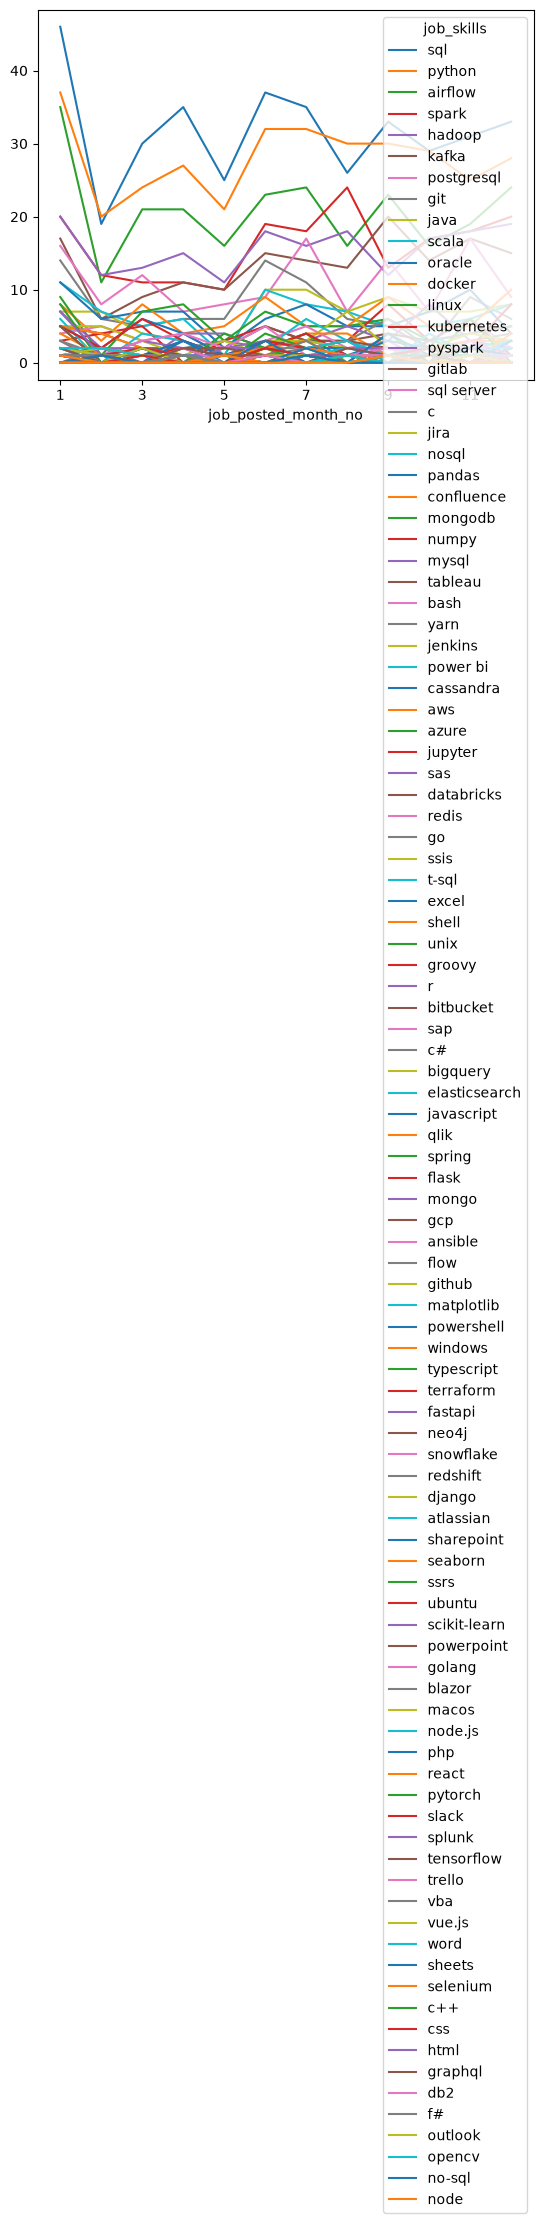

In [40]:
df_DE_RUS_pivot.plot(kind= 'line')

In [ ]:
DE_totals = df_DE_RUS.groupby('job_posted_month_no').size()

In [51]:
DE_totals

job_posted_month_no
1     52
2     25
3     33
4     40
5     32
6     40
7     45
8     38
9     45
10    35
11    37
12    42
dtype: int64

In [62]:
df_DE_RUS_percent = (df_DE_RUS_pivot.div(DE_totals, axis=0) * 100).round(1)

In [63]:
df_DE_RUS_percent = df_DE_RUS_percent.reset_index()
df_DE_RUS_percent['job_posted_month'] = df_DE_RUS_percent['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DE_RUS_percent = df_DE_RUS_percent.set_index('job_posted_month')
df_DE_RUS_percent = df_DE_RUS_percent.drop(columns='job_posted_month_no')

In [64]:
df_DE_RUS_percent

job_skills,sql,python,airflow,spark,hadoop,kafka,postgresql,git,java,scala,...,c++,css,html,graphql,db2,f#,outlook,opencv,no-sql,node
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,88.5,71.2,67.3,38.5,38.5,32.7,30.8,26.9,13.5,21.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Feb,76.0,80.0,44.0,48.0,48.0,24.0,32.0,24.0,28.0,28.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Mar,90.9,72.7,63.6,33.3,39.4,27.3,36.4,15.2,12.1,15.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Apr,87.5,67.5,52.5,27.5,37.5,27.5,17.5,15.0,7.5,15.0,...,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,0.0,0.0
May,78.1,65.6,50.0,31.2,34.4,31.2,25.0,18.8,3.1,3.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Jun,92.5,80.0,57.5,47.5,45.0,37.5,22.5,35.0,25.0,25.0,...,0.0,2.5,0.0,0.0,2.5,0.0,0.0,0.0,0.0,0.0
Jul,77.8,71.1,53.3,40.0,35.6,31.1,37.8,24.4,22.2,17.8,...,2.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.2,0.0
Aug,68.4,78.9,42.1,63.2,47.4,34.2,18.4,15.8,18.4,18.4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.6,0.0,0.0
Sep,73.3,66.7,51.1,28.9,26.7,44.4,31.1,11.1,20.0,11.1,...,0.0,0.0,2.2,0.0,0.0,0.0,2.2,0.0,0.0,2.2


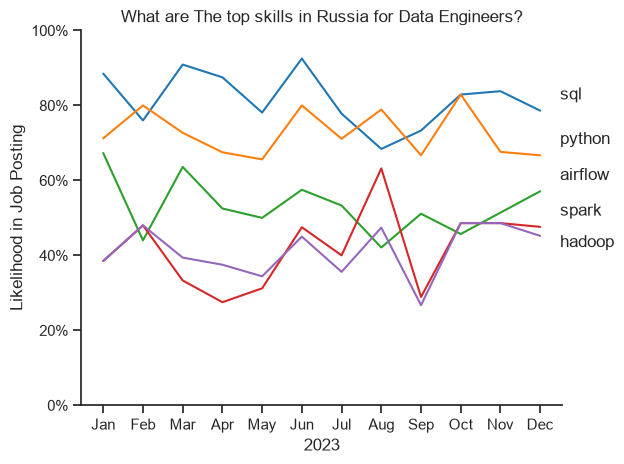

In [129]:
df_plot = df_DE_RUS_percent.iloc[:,:5]
sns.set_theme(style='ticks')
sns.lineplot(df_plot, legend=False, dashes=False, palette='tab10')
sns.despine()
plt.title('What are The top skills in Russia for Data Engineers?')
plt.xlabel('2023')
plt.ylabel('Likelihood in Job Posting')
plt.ylim(0,100)
from matplotlib.ticker import PercentFormatter
ax=plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter())
#ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos:f'{int(y)}%'))
for i in range(4):
    plt.text(11.5, df_plot.iloc[-1, i]+3, df_plot.columns[i])
plt.text(11.5, df_plot.iloc[-1, 4]-3,df_plot.columns[4])

plt.tight_layout()